<a href="https://colab.research.google.com/github/Shanzahra-png/high-frequency-volatility-forecasting/blob/main/HAR_RV_pipeline_v1_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HAR-RV Volatility Forecasting Pipeline (v1.2: all assets and all test periods in one run)
**Binance spot 1-minute data → daily realized variance → HAR models with calendar effects → out-of-sample evaluation → replication across assets and periods**

| | |
|---|---|
| **Author** | Shanz · MPhil Data Science, Bahauddin Zakariya University |
| **Version** | 1.2 (16 Nov 2026). Runs every asset in `SYMBOLS` and scores every period in `TEST_PERIODS` in a single Run all. No manual edits between runs |
| **Environment** | Google Colab, a CPU runtime is enough. Uses pandas, numpy, statsmodels, scipy, matplotlib |
| **Run time** | First run about 10-25 min (downloads, only for months not yet cached). Re-runs about 3-5 min |
| **How to run** | Edit the configuration cell (Section 0), then Runtime → Run all |

---

## 1. Purpose
Forecast the **daily realized variance (RV)** of crypto assets and test, with out-of-sample statistics, which ingredients of the HAR-RV model improve forecasts, and whether the findings **replicate across assets and time periods**:

1. the classic daily / weekly / monthly lag structure (HAR),
2. calendar effects (Saturday, Sunday and Monday dummies),
3. the estimation scheme (expanding window vs fixed rolling window),
4. the forecast horizon (1, 7 and 28 days).

## 2. Method in brief
| Step | Definition |
|---|---|
| Realized variance | RV of day *t* = sum of squared 1-minute log returns within that UTC day. Returns across data gaps and month boundaries are kept (they carry the variance of the elapsed time). |
| Target | `y` = log of the mean RV over the next *h* days (for *h* = 1: log RV of tomorrow). |
| Features | `f_d` = log RV today, `f_w` / `f_m` = mean of the last *w* / *m* daily log RVs. *h* = 1 uses (5, 22). *h* = 7 and 28 use (7, 28), so each window contains every weekday equally often. |
| Calendar dummies | Saturday, Sunday and Monday of the **target** day (known in advance, no look-ahead). Used for *h* = 1 only. |
| Estimation | OLS re-fitted **every day** on data fully known at the forecast origin. Default: rolling window of 730 days. |
| Losses | Squared error of log RV (**log-MSE**) and **QLIKE** (Patton, 2011). QLIKE forecasts use `exp(prediction + s²/2)` (`s²` = residual variance of the same fit) because `exp(prediction)` is the median, not the mean, of RV. |
| Tests | Diebold-Mariano (non-nested pairs) and Clark-West (nested pairs, log-MSE only), Newey-West (HAC) standard errors. |

## 3. How "all periods in one run" works
A forecast for day *t* uses only data before *t*, so it does not depend on which test period you evaluate afterwards. The notebook therefore makes every forecast **once** for the whole span from the earliest period start to the end of the data, and each entry of `TEST_PERIODS` simply selects which forecasts are scored. Results are identical to running each period separately, just faster and with no edits between runs.

## 4. Pipeline stages
| Section | What happens |
|---|---|
| 0 | Configuration, imports, Drive mount |
| 1 | Download monthly zips from `data.binance.vision` (cached), stitch into daily RV per asset |
| 2 | Data validation per asset: missing days, gap days, plot |
| 3 | Features and period selection |
| 4 | Forecast engine, losses, DM and Clark-West tests |
| 5 | In-sample weekday diagnostics per asset |
| 6 | `run_symbol`: one asset end to end (forecast once, score every period, save everything) |
| 7 | Run all assets, then the replication scorecard across assets and periods |

Files go to `MyDrive/<DRIVE_FOLDER>/output/<SYMBOL>/` (daily RV, figures, yearly weekday table) and `.../<SYMBOL>/periods/<period>/` (results per horizon, `tests.csv`, `primary_tests.csv`, `window_sensitivity.csv`). The cross-asset table is `output/replication_all.csv`.

## 5. Conventions
* **No look-ahead.** Training rows for a forecast made at the end of day *t* are those with origin ≤ *t* − *h* (target fully known). Features use information up to day *t*.
* **Period selection.** A forecast belongs to a period if its first target day is on or after the period start and its last target day is on or before the period end (`None` = end of data).
* **Sign convention.** "A vs B" with a **positive** statistic means model A has the lower loss. DM p-values are two-sided; Clark-West p-values are one-sided.
* **Primary tests.** Five hypotheses were fixed after the BTC 2025-26 run (see Section 6 of this notebook). Holm correction is applied over these five, separately for each asset and period. A test **passes** when its statistic is positive and its Holm p-value is below 0.05. Test 5 (h = 28) is exploratory.
* **Overlapping forecasts.** For *h* > 1 consecutive errors overlap, so HAC lags equal *h* and the effective sample is about *n / h* windows. Treat borderline p-values at *h* = 28 as indicative only.

## 6. Known limitations
* BTC and ETH volatility move together, so they are not independent samples. Different time periods add more independence than a second asset.
* The weekday-dummy specification and the window grid were chosen after looking at BTC 2025-26 data. Out-of-sample forecasts use only past data, but the *choice* of specification is not fully out-of-sample. That is why the other periods are used as replications.
* Nested-model tests are conservative with estimated parameters, hence Clark-West.
* Days with missing minutes are flagged, not dropped (dropping would break the calendar-day rolling windows).
* No jump separation, microstructure-noise correction or intraday seasonality. Nothing here is trading advice.

## 7. References
* Corsi, F. (2009). A simple approximate long-memory model of realized volatility. *Journal of Financial Econometrics*.
* Andersen, Bollerslev, Diebold & Labys (2003). Modeling and forecasting realized volatility. *Econometrica*.
* Patton, A. (2011). Volatility forecast comparison using imperfect volatility proxies. *Journal of Econometrics*.
* Diebold, F. & Mariano, R. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*.
* Clark, T. & West, K. (2007). Approximately normal tests for equal predictive accuracy in nested models. *Journal of Econometrics*.


---
## Section 0 · Configuration
The **only cell you normally edit**.

In [1]:
# ============================ EDIT HERE ============================
SYMBOLS      = ["BTCUSDT", "ETHUSDT"]   # every asset is run, one after the other
START_MONTH  = "2020-01"                # first monthly file (data exist from 2017-08)
END_MONTH    = "2026-10"                # fixed so every rerun uses identical data; None = last complete month
TEST_PERIODS = {                        # name: (first target day, last target day or None for end of data)
    "2023-24": ("2023-01-01", "2024-12-31"),
    "2025-26": ("2025-01-01", None),
    "2023-26_pooled": ("2023-01-01", None),   # both periods together: more power, but not independent of the two above
}
WINDOW       = 730                      # rolling re-fit window in days (None = expanding)
WINDOW_GRID  = [None, 1095, 730, 365]   # windows compared in the sensitivity table
HORIZONS     = [1, 7, 28]               # forecast horizons in days
FEATURE_WINDOWS = {1: (5, 22), 7: (7, 28), 28: (7, 28)}   # (weekly, monthly) averaging lengths per horizon
HAC_LAGS     = {1: 5, 7: 7, 28: 28}                       # Newey-West lags per horizon
DRIVE_FOLDER = "HF"                     # folder in My Drive for cache and outputs
N_WORKERS    = 4                        # parallel downloads
FORCE_REDOWNLOAD = False                # True = ignore the monthly cache
VERBOSE      = False                    # True = print every table for every asset and period
EXISTING_DAILY_CSV = {}                 # optional, e.g. {"BTCUSDT": "/content/drive/MyDrive/HF/btc_daily_rv.csv"}
# ===================================================================


In [2]:
import io, json, time, zipfile, warnings, platform
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import statsmodels
import statsmodels.api as sm
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests
from tqdm.auto import tqdm
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive") / DRIVE_FOLDER
except ImportError:
    BASE = Path("./HF_output")                      # running outside Colab

ROOT_OUT, CACHE_ROOT = BASE / "output", BASE / "cache"
ROOT_OUT.mkdir(parents=True, exist_ok=True)
END_MONTH = END_MONTH or str(pd.Timestamp.now(tz="UTC").tz_localize(None).to_period("M") - 1)
print(f"Assets {SYMBOLS} | months {START_MONTH} .. {END_MONTH} | periods {list(TEST_PERIODS)} | window {WINDOW}")
print("Outputs ->", ROOT_OUT)


Mounted at /content/drive
Assets ['BTCUSDT', 'ETHUSDT'] | months 2020-01 .. 2026-10 | periods ['2023-24', '2025-26', '2023-26_pooled'] | window 730
Outputs -> /content/drive/MyDrive/HF/output


---
## Section 1 · Data acquisition and daily realized variance
For each asset and month the notebook downloads `<SYMBOL>-1m-YYYY-MM.zip`, reads the open time and close price, computes 1-minute log returns and sums their squares per UTC day. Per-month results are cached as small JSON files (the same cache the earlier versions used), so nothing already downloaded is fetched again.

* **Time unit.** Files switched from milliseconds to microseconds (16-digit timestamps) in 2025. Detected per file.
* **Month boundaries.** The return from the last close of one month to the first close of the next is added to the first day of the new month. A missing month breaks the chain instead of being bridged.

In [3]:
BASE_URL = "https://data.binance.vision/data/spot/monthly/klines/{s}/1m/{s}-1m-{m}.zip"
COLS = ["open_time", "open", "high", "low", "close", "volume", "close_time",
        "quote_volume", "trades", "taker_buy_base", "taker_buy_quote", "ignore"]
FAILED, MISSING = [], []


def download_zip(symbol, month, retries=4):
    """Bytes of one monthly zip; None if Binance has no such file (HTTP 404)."""
    url = BASE_URL.format(s=symbol, m=month)
    last_err = None
    for k in range(retries):
        try:
            r = requests.get(url, timeout=120)
            if r.status_code == 404:
                return None
            r.raise_for_status()
            return r.content
        except requests.RequestException as e:
            last_err = e
            time.sleep(2 ** k)
    raise RuntimeError(f"download failed after {retries} tries: {last_err}")


def parse_zip(content):
    """One month of 1-minute klines -> per-day RV and the first/last close."""
    with zipfile.ZipFile(io.BytesIO(content)) as z:
        with z.open(z.namelist()[0]) as f:
            raw = pd.read_csv(f, header=None, names=COLS, usecols=["open_time", "close"])
    t = pd.to_numeric(raw["open_time"], errors="coerce")
    ok = t > 10**12                                  # drops a header row and any corrupt row (valid times are > year 2001)
    raw, t = raw[ok], t[ok].astype("int64")
    unit = "us" if t.iloc[0] >= 10**15 else "ms"     # microseconds from 2025 on
    idx = pd.to_datetime(t.to_numpy(), unit=unit, utc=True)
    close = pd.Series(raw["close"].astype(float).to_numpy(), index=idx).sort_index()
    close = close[~close.index.duplicated(keep="first")]
    ret = np.log(close).diff().dropna()
    day = ret.index.floor("D")
    g = pd.DataFrame({"rv": (ret ** 2).groupby(day).sum(), "n_ret": ret.groupby(day).count()})
    g.index.name = "day"
    return {"daily": g, "first_close": float(close.iloc[0]), "last_close": float(close.iloc[-1]),
            "first_day": close.index[0].floor("D")}


def save_cache(path, rec):
    d = rec["daily"].reset_index()
    d["day"] = d["day"].map(lambda x: x.isoformat())
    obj = {"daily": d.to_dict("records"), "first_close": rec["first_close"],
           "last_close": rec["last_close"], "first_day": rec["first_day"].isoformat()}
    path.write_text(json.dumps(obj))


def load_cache(path):
    obj = json.loads(path.read_text())
    g = pd.DataFrame(obj["daily"])
    g["day"] = pd.to_datetime(g["day"], utc=True)
    return {"daily": g.set_index("day"), "first_close": obj["first_close"],
            "last_close": obj["last_close"], "first_day": pd.Timestamp(obj["first_day"])}


def get_month(symbol, month):
    f = CACHE_ROOT / symbol / f"{month}.json"
    f.parent.mkdir(parents=True, exist_ok=True)
    if f.exists() and not FORCE_REDOWNLOAD:
        return load_cache(f)
    try:
        content = download_zip(symbol, month)
    except Exception as e:
        FAILED.append((symbol, month, str(e)))
        return None
    if content is None:
        MISSING.append((symbol, month))
        return None
    rec = parse_zip(content)
    save_cache(f, rec)
    return rec


def assemble(months, recs):
    """Stitch monthly records into one daily table, adding the month-boundary returns."""
    frames, prev_last = [], None
    for m, rec in zip(months, recs):
        if rec is None:
            prev_last = None                      # never bridge over a missing month
            continue
        g = rec["daily"].copy()
        if prev_last is not None:
            r = np.log(rec["first_close"]) - np.log(prev_last)
            fd = rec["first_day"]
            if fd not in g.index:
                g.loc[fd] = [0.0, 0]
                g = g.sort_index()
            g.loc[fd, "rv"] += r ** 2
            g.loc[fd, "n_ret"] += 1
        prev_last = rec["last_close"]
        frames.append(g)
    daily = pd.concat(frames).sort_index()
    daily["n_ret"] = daily["n_ret"].astype(int)
    daily.index = pd.DatetimeIndex(daily.index).as_unit("ns")
    return daily


def get_daily(symbol):
    """Daily RV table for one asset (from the cache / Binance, or from an existing csv)."""
    out_dir = ROOT_OUT / symbol
    out_dir.mkdir(parents=True, exist_ok=True)
    ex = EXISTING_DAILY_CSV.get(symbol)
    if ex and Path(ex).exists():
        daily = pd.read_csv(ex, index_col=0, parse_dates=True)[["rv", "n_ret"]]
        daily.index = pd.DatetimeIndex(pd.to_datetime(daily.index, utc=True)).as_unit("ns")
        daily.index.name = "day"
        print(f"{symbol}: loaded existing daily table {ex}")
    else:
        months = [str(p) for p in pd.period_range(START_MONTH, END_MONTH, freq="M")]
        with ThreadPoolExecutor(N_WORKERS) as pool:
            recs = list(tqdm(pool.map(lambda m: get_month(symbol, m), months), total=len(months), desc=symbol))
        daily = assemble(months, recs)
        miss = [m for s, m in MISSING if s == symbol]
        fail = [(m, e) for s, m, e in FAILED if s == symbol]
        if miss:
            print(f"{symbol}: not published (HTTP 404):", miss)
        if fail:
            print(f"{symbol}: FAILED downloads (run again, the cache keeps finished months):", fail)
    daily.to_csv(out_dir / f"{symbol}_daily_rv.csv")
    return daily


---
## Section 2 · Data validation
Per asset: is the calendar complete, are the values sane, which days have missing minutes? The result is printed in a few lines and a plot is saved.

In [4]:
def validate(symbol, daily):
    daily = daily.copy()
    daily["rv_vol"] = np.sqrt(daily["rv"])
    full_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
    missing_days = full_days.difference(daily.index)
    expected_n = pd.Series(1440, index=daily.index)
    expected_n.iloc[0] = daily["n_ret"].iloc[0]          # the first sample day has no previous close, not judged
    daily["gap_day"] = daily["n_ret"] < expected_n
    bad_values = int((~np.isfinite(daily["rv"]) | (daily["rv"] <= 0)).sum())
    outside = 0
    if not EXISTING_DAILY_CSV.get(symbol):
        lo = pd.Timestamp(START_MONTH + "-01", tz="UTC")
        hi = pd.Period(END_MONTH, "M").end_time.tz_localize("UTC")
        outside = int(((daily.index < lo) | (daily.index > hi)).sum())
    flag = lambda ok: "OK" if ok else "WARNING"
    print(f"[{symbol}] {len(daily)} days {daily.index.min().date()} .. {daily.index.max().date()} | "
          f"missing days {len(missing_days)} {flag(len(missing_days) == 0)} | bad RV values {bad_values} {flag(bad_values == 0)} | "
          f"outside range {outside} {flag(outside == 0)} | gap days {int(daily['gap_day'].sum())} ({daily['gap_day'].mean():.1%})")
    if VERBOSE:
        display(daily.loc[daily["gap_day"], ["rv", "n_ret", "rv_vol"]].sort_values("n_ret").head(10))
    fig_dir = ROOT_OUT / symbol / "figures"
    fig_dir.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(daily.index, daily["rv_vol"], lw=0.8, label="daily realized volatility")
    g = daily["gap_day"]
    ax.scatter(daily.index[g], daily.loc[g, "rv_vol"], s=14, c="red", zorder=3, label="gap day (missing minutes)")
    ax.set_yscale("log"); ax.set_ylabel("sqrt(RV), log scale"); ax.set_title(f"{symbol}: daily realized volatility")
    ax.legend(); ax.grid(alpha=0.3)
    fig.savefig(fig_dir / "01_daily_realized_vol.png", dpi=150, bbox_inches="tight")
    plt.show()
    return daily


---
## Section 3 · Features and period selection
One row per **forecast origin** *t* (information up to the end of day *t*). The target is the log of the mean RV over days *t*+1 … *t*+*h*. For *h* = 1 the calendar dummies describe day *t*+1. `naive` is the trailing *h*-day mean RV (for *h* = 1: today's RV).

`period_selection` marks which origins belong to a test period: first target day on or after the period start and last target day on or before the period end.

In [5]:
def make_dataset(daily, h, w, m):
    """Feature table, one row per forecast origin day t."""
    full = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
    rv = daily["rv"].reindex(full)                      # missing days become NaN, never silently skipped
    lr = np.log(rv)
    out = pd.DataFrame(index=full)
    out["y"]     = np.log(rv.rolling(h).mean().shift(-h))   # log mean RV over t+1..t+h
    out["f_d"]   = lr                                       # log RV today
    out["f_w"]   = lr.rolling(w).mean()                     # mean log RV, last w days
    out["f_m"]   = lr.rolling(m).mean()                     # mean log RV, last m days
    out["naive"] = np.log(rv.rolling(h).mean())             # trailing h-day mean RV
    dow = (out.index + pd.Timedelta(days=1)).dayofweek      # weekday of the first target day (0 = Monday)
    out["weekend"] = (dow >= 5).astype(int)
    out["sat"] = (dow == 5).astype(int)
    out["sun"] = (dow == 6).astype(int)
    out["mon"] = (dow == 0).astype(int)
    out = out.dropna()
    out.attrs["h"] = h
    return out


def period_selection(origins, h, start, end):
    """Boolean mask over forecast origins that belong to the period (end = None: end of data)."""
    keep = np.asarray((origins + pd.Timedelta(days=1)) >= pd.Timestamp(start, tz="UTC"))
    if end:
        keep &= np.asarray((origins + pd.Timedelta(days=h)) <= pd.Timestamp(end, tz="UTC"))
    return keep


---
## Section 4 · Forecast engine, losses and tests
* `rolling_forecast` re-fits OLS at every origin using only rows whose target was fully known (origin ≤ *t* − *h*), optionally limited to the last `window` rows. It returns the log forecast and the variance-corrected log forecast `p + s²/2`.
* Model specs: a list of columns (regression with the default `WINDOW`), `("direct", column)` (benchmark without estimation) or `("reg", columns, window)` (regression with its own window).
* `dm_test` and `cw_test`: a **positive statistic means the first-named model is better**.

In [6]:
def rolling_forecast(df, cols, h, origins, window):
    """Rolling OLS forecasts for every origin (numpy, fast)."""
    X = df[cols].to_numpy(float)
    y = df["y"].to_numpy(float)
    idx = df.index
    pos = idx.get_indexer(origins)
    cut = idx.searchsorted(origins - pd.Timedelta(days=h), side="right")    # rows with origin <= t - h
    p, s2 = np.empty(len(pos)), np.empty(len(pos))
    for k, (i, j) in enumerate(zip(pos, cut)):
        lo = 0 if window is None else max(0, j - window)
        n = j - lo
        if n < len(cols) + 30:
            raise ValueError(f"too few training rows ({n}) at origin {idx[i].date()}; start the data earlier or move the period later")
        A = np.column_stack([np.ones(n), X[lo:j]])
        yy = y[lo:j]
        beta = np.linalg.lstsq(A, yy, rcond=None)[0]
        r = yy - A @ beta
        s2[k] = r @ r / (n - A.shape[1])
        p[k] = beta[0] + X[i] @ beta[1:]
    p = pd.Series(p, index=origins)
    return p, p + pd.Series(s2, index=origins) / 2


def losses(y, p, pc):
    """Per-day log-MSE loss and QLIKE loss (all inputs are log values; pc is the bias-corrected forecast)."""
    lm = (y - p) ** 2
    z = y - pc                      # log(RV / forecast)
    lq = np.exp(z) - z - 1          # QLIKE
    return lm, lq


def forecast_all(df, models, h, origins):
    """All forecasts for every origin of the whole span, made once."""
    y = df.loc[origins, "y"]
    P, PC = {}, {}
    for name, spec in models.items():
        if isinstance(spec, tuple) and spec[0] == "direct":
            p = df.loc[origins, spec[1]]
            pc = p
        elif isinstance(spec, tuple) and spec[0] == "reg":
            p, pc = rolling_forecast(df, spec[1], h, origins, spec[2])
        else:
            p, pc = rolling_forecast(df, spec, h, origins, WINDOW)
        P[name], PC[name] = p, pc
    return y, P, PC


def score(y, P, PC, sel):
    """Select the origins of one period and compute the per-day losses of every model."""
    ys = y[sel]
    Ps = {k: v[sel] for k, v in P.items()}
    LM, LQ = {}, {}
    for k in P:
        LM[k], LQ[k] = losses(ys, Ps[k], PC[k][sel])
    return ys, Ps, LM, LQ


def loss_table(LM, LQ, names):
    return pd.DataFrame({n: {"MSE (log)": LM[n].mean(), "QLIKE": LQ[n].mean()} for n in names}).T


def add_relative(tab, ref):
    tab = tab.copy()
    tab[f"MSE vs {ref} (%)"] = (tab["MSE (log)"] / tab.loc[ref, "MSE (log)"] - 1) * 100
    tab[f"QLIKE vs {ref} (%)"] = (tab["QLIKE"] / tab.loc[ref, "QLIKE"] - 1) * 100
    return tab


def dm_test(loss_base, loss_alt, lags):
    """Diebold-Mariano. Positive statistic = alt has the lower loss. Two-sided p-value."""
    d = np.asarray(loss_base, float) - np.asarray(loss_alt, float)
    r = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return float(r.tvalues[0]), float(r.pvalues[0])


def cw_test(y, p_small, p_large, lags):
    """Clark-West for nested models (log-MSE only). One-sided p-value: small = the larger model adds information."""
    y, ps, pl = (np.asarray(v, float) for v in (y, p_small, p_large))
    f = (y - ps) ** 2 - ((y - pl) ** 2 - (ps - pl) ** 2)
    r = sm.OLS(f, np.ones(len(f))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    t = float(r.tvalues[0])
    return t, float(norm.sf(t))


def log_test(tests, h, comparison, metric, test, stat, p):
    tests.append({"h": h, "comparison": comparison, "metric": metric, "test": test, "statistic": stat, "p_value": p})


# ---------------- model sets ----------------
H1_COLS = {
    "AR(1)":               ["f_d"],
    "HAR":                 ["f_d", "f_w", "f_m"],
    "HAR + weekend":       ["f_d", "f_w", "f_m", "weekend"],
    "HAR + sat/sun/mon":   ["f_d", "f_w", "f_m", "sat", "sun", "mon"],
    "AR(1) + sat/sun/mon": ["f_d", "sat", "sun", "mon"],
}
MULTI_MODELS = {
    "Naive (trailing mean)": ("direct", "naive"),
    "AR(1) [f_d]":           ["f_d"],
    "Week only [f_w]":       ["f_w"],
    "Month only [f_m]":      ["f_m"],
    "HAR":                   ["f_d", "f_w", "f_m"],
}
wlabel = lambda w: "expanding" if w is None else f"{w}d"
WINDOWS_NEEDED = sorted(set(WINDOW_GRID) | {None, WINDOW}, key=lambda x: (x is None, x or 0))


def h1_models():
    models = {"Naive (yesterday)": ("direct", "naive"), "Mean of last 22 days": ("direct", "f_m")}
    models.update(H1_COLS)
    for name in ("HAR", "HAR + sat/sun/mon"):           # window sensitivity, computed once with the rest
        for w in WINDOWS_NEEDED:
            models[f"{name} @ {wlabel(w)}"] = ("reg", H1_COLS[name], w)
    return models


def tests_h1(tests, ys, Ps, LM, LQ):
    lag = HAC_LAGS.get(1, 5)
    for A, B in [("HAR + sat/sun/mon", "HAR"), ("HAR + sat/sun/mon", "HAR + weekend"),
                 ("HAR + sat/sun/mon", "AR(1) + sat/sun/mon"), ("HAR + sat/sun/mon", "Naive (yesterday)"),
                 ("HAR", "AR(1)")]:
        for metric, L in (("log-MSE", LM), ("QLIKE", LQ)):
            t, pv = dm_test(L[B], L[A], lag)
            log_test(tests, 1, f"{A} vs {B}", metric, "Diebold-Mariano (two-sided)", t, pv)
    for small, large in [("AR(1)", "HAR"), ("AR(1) + sat/sun/mon", "HAR + sat/sun/mon"),
                         ("HAR", "HAR + weekend"), ("HAR + weekend", "HAR + sat/sun/mon")]:
        t, pv = cw_test(ys, Ps[small], Ps[large], lag)
        log_test(tests, 1, f"{large} vs {small} (nested)", "log-MSE", "Clark-West (one-sided)", t, pv)
    if WINDOW is not None:
        b, a = "HAR + sat/sun/mon @ expanding", "HAR + sat/sun/mon"
        for metric, L in (("log-MSE", LM), ("QLIKE", LQ)):
            t, pv = dm_test(L[b], L[a], lag)
            log_test(tests, 1, f"HAR + sat/sun/mon: {WINDOW}d window vs expanding", metric, "Diebold-Mariano (two-sided)", t, pv)


def tests_multi(tests, h, ys, Ps, LM, LQ):
    lag = HAC_LAGS.get(h, h)
    for small in ["AR(1) [f_d]", "Week only [f_w]", "Month only [f_m]"]:
        t, pv = cw_test(ys, Ps[small], Ps["HAR"], lag)
        log_test(tests, h, f"HAR vs {small} (nested)", "log-MSE", "Clark-West (one-sided)", t, pv)
        t, pv = dm_test(LQ[small], LQ["HAR"], lag)
        log_test(tests, h, f"HAR vs {small}", "QLIKE", "Diebold-Mariano (two-sided)", t, pv)
    for metric, L in (("log-MSE", LM), ("QLIKE", LQ)):
        t, pv = dm_test(L["Naive (trailing mean)"], L["HAR"], lag)
        log_test(tests, h, "HAR vs Naive (trailing mean)", metric, "Diebold-Mariano (two-sided)", t, pv)


# ---------------- the five primary tests ----------------
PRIMARY = [   # label, horizon, regex for the comparison text, metric
    ("1. dummies vs HAR (h=1)",                    1,  r"^HAR \+ sat/sun/mon vs HAR$",              "log-MSE"),
    ("2. fixed window vs expanding (h=1)",         1,  r"window vs expanding$",                     "log-MSE"),
    ("3. HAR vs AR(1), nested (h=1)",              1,  r"^HAR vs AR\(1\) \(nested\)$",              "log-MSE"),
    ("4. HAR vs weekly-only, nested (h=7)",        7,  r"^HAR vs Week only \[f_w\] \(nested\)$",    "log-MSE"),
    ("5. HAR vs weekly-only, nested (h=28) [exploratory]", 28, r"^HAR vs Week only \[f_w\] \(nested\)$", "log-MSE"),
]


def primary_table(tests):
    rows = []
    for label, h, pat, metric in PRIMARY:
        m = tests[(tests["h"] == h) & (tests["metric"] == metric) & tests["comparison"].str.contains(pat, regex=True)]
        rows.append({"test": label,
                     "statistic": m["statistic"].iloc[0] if len(m) else np.nan,
                     "p_value": m["p_value"].iloc[0] if len(m) else np.nan})
    t = pd.DataFrame(rows)
    ok = t["p_value"].notna()
    t["p_holm"] = np.nan
    if ok.any():
        t.loc[ok, "p_holm"] = multipletests(t.loc[ok, "p_value"], method="holm")[1]
    t["passes"] = (t["statistic"] > 0) & (t["p_holm"] < 0.05)
    return t


---
## Section 5 · In-sample weekday diagnostics (per asset, h = 1)
Full-sample regressions used to **understand** the data, not forecasting results. A dummy coefficient *c* multiplies variance by `exp(c)` and volatility by `exp(c/2)`. The yearly table shows whether the weekday effects are stable over time (with HAC standard errors).

In [7]:
def diagnostics(symbol, df1):
    X_HAR, X_DUM = ["f_d", "f_w", "f_m"], ["sat", "sun", "mon"]
    lag = HAC_LAGS.get(1, 5)
    fit = sm.OLS(df1["y"], sm.add_constant(df1[X_HAR + X_DUM])).fit(cov_type="HAC", cov_kwds={"maxlags": lag})
    vol = np.exp(fit.params[X_DUM] / 2)
    print(f"[{symbol}] full-sample HAR + sat/sun/mon: R2 {fit.rsquared:.3f} | persistence {fit.params[X_HAR].sum():.3f} | "
          f"volatility multipliers vs Tue-Fri: Sat x{vol['sat']:.2f}, Sun x{vol['sun']:.2f}, Mon x{vol['mon']:.2f}")
    if VERBOSE:
        display(pd.DataFrame({"coef": fit.params, "HAC s.e.": fit.bse, "t": fit.tvalues, "p": fit.pvalues}).round(4))
    yr = (df1.index + pd.Timedelta(days=1)).year          # grouped by TARGET day year
    rows = []
    for year, g in df1.groupby(yr):
        if len(g) < 100:
            continue
        r = sm.OLS(g["y"], sm.add_constant(g[X_HAR + X_DUM])).fit(cov_type="HAC", cov_kwds={"maxlags": lag})
        rows.append({"year": year, "n": len(g), **{k: r.params[k] for k in X_DUM}, **{k + "_se": r.bse[k] for k in X_DUM}})
    yearly = pd.DataFrame(rows).set_index("year")
    print(f"[{symbol}] weekday dummy coefficients by year (HAC s.e.):")
    display(yearly.round(3))
    fig_dir = ROOT_OUT / symbol / "figures"
    fig, ax = plt.subplots(figsize=(9, 4))
    for k, c in zip(X_DUM, ["tab:red", "tab:blue", "tab:green"]):
        ax.plot(yearly.index, yearly[k], marker="o", color=c, label=k)
        ax.fill_between(yearly.index, yearly[k] - 1.96 * yearly[k + "_se"], yearly[k] + 1.96 * yearly[k + "_se"], color=c, alpha=0.15)
    ax.axhline(0, color="k", lw=0.8); ax.grid(alpha=0.3); ax.legend()
    ax.set_xlabel("year"); ax.set_ylabel("coefficient on log RV")
    ax.set_title(f"{symbol}: weekday effects by year (bands = 95% interval)")
    fig.savefig(fig_dir / "02_weekday_effects_by_year.png", dpi=150, bbox_inches="tight")
    plt.show()
    yearly.to_csv(ROOT_OUT / symbol / "yearly_weekday_effects.csv")
    return yearly


---
## Section 6 · One asset end to end: forecast once, score every period
`run_symbol(symbol)`:
1. builds the daily RV table and validates it,
2. runs the weekday diagnostics,
3. makes **all forecasts once** for the span from the earliest period start to the end of the data (every model, every horizon, every window in the grid),
4. for each period in `TEST_PERIODS`: selects the forecasts that belong to it, builds the loss tables, runs all tests, applies Holm to the five primary tests and saves everything under `output/<SYMBOL>/periods/<period>/`,
5. saves the forecast plots.

**Primary hypotheses** (fixed after the BTC 2025-26 run, so every other asset or period is a replication):
1. Calendar dummies (Sat/Sun/Mon) improve on plain HAR at h = 1.
2. A fixed rolling window beats an expanding window at h = 1.
3. HAR beats AR(1) at h = 1 (Clark-West).
4. HAR beats the weekly-average-only model at h = 7 (Clark-West).
5. HAR beats the weekly-average-only model at h = 28 (Clark-West). **Exploratory**: it did not hold on BTC.

Holm correction is over these five only, separately for each asset and period. A test **passes** when its statistic is positive and its Holm p-value is below 0.05.

In [8]:
def run_symbol(symbol):
    daily = validate(symbol, get_daily(symbol))
    sym_dir = ROOT_OUT / symbol
    horizons = sorted(set(HORIZONS) | {1})
    DS = {h: make_dataset(daily, h, *FEATURE_WINDOWS.get(h, (7, 28))) for h in horizons}
    diagnostics(symbol, DS[1])

    # ---- 1. all forecasts, once, for the whole span ----
    span_start = min(pd.Timestamp(s, tz="UTC") for s, _ in TEST_PERIODS.values())
    FC = {}
    for h in horizons:
        df = DS[h]
        origins = df.index[np.asarray((df.index + pd.Timedelta(days=1)) >= span_start)]
        models = h1_models() if h == 1 else MULTI_MODELS
        FC[h] = (df, origins) + forecast_all(df, models, h, origins)

    # ---- 2. score every period ----
    results = {}
    for pname, (ps, pe) in TEST_PERIODS.items():
        pdir = sym_dir / "periods" / pname
        pdir.mkdir(parents=True, exist_ok=True)
        tests, info = [], {}
        for h in horizons:
            df, origins, y, P, PC = FC[h]
            sel = period_selection(origins, h, ps, pe)
            if sel.sum() < 30:
                print(f"[{symbol} {pname}] h={h}: only {int(sel.sum())} forecasts in this period, skipped")
                continue
            ys, Ps, LM, LQ = score(y, P, PC, sel)
            info[h] = int(sel.sum())
            if h == 1:
                main = [n for n in P if "@" not in n]
                tab = add_relative(loss_table(LM, LQ, main), "HAR")
                wtab = pd.DataFrame([{"model": n.split(" @ ")[0], "window": n.split(" @ ")[1],
                                      "MSE (log)": LM[n].mean(), "QLIKE": LQ[n].mean()} for n in P if "@" in n])
                wtab.to_csv(pdir / "window_sensitivity.csv", index=False)
                tests_h1(tests, ys, Ps, LM, LQ)
                if VERBOSE:
                    print(f"\n[{symbol} {pname}] h=1, {int(sel.sum())} forecasts, window {wlabel(WINDOW)}")
                    display(tab.round(4))
                    order = [wlabel(w) for w in WINDOWS_NEEDED]
                    display(wtab.pivot(index="window", columns="model", values=["MSE (log)", "QLIKE"]).reindex(order).round(4))
            else:
                tab = add_relative(loss_table(LM, LQ, list(P)), "HAR")
                tests_multi(tests, h, ys, Ps, LM, LQ)
                if VERBOSE:
                    print(f"\n[{symbol} {pname}] h={h}, {int(sel.sum())} forecasts (about {int(sel.sum()) // h} independent windows)")
                    display(tab.round(4))
            tab.round(6).to_csv(pdir / f"results_h{h}.csv")
        tests_df = pd.DataFrame(tests)
        tests_df["p_holm_all"] = multipletests(tests_df["p_value"], method="holm")[1]
        prim = primary_table(tests_df)
        tests_df.to_csv(pdir / "tests.csv", index=False)
        prim.to_csv(pdir / "primary_tests.csv", index=False)
        print(f"\n[{symbol} | period {pname} ({ps} .. {pe or 'end of data'}) | forecasts per horizon {info}] primary tests:")
        with pd.option_context("display.float_format", "{:.4g}".format):
            display(prim)
        if VERBOSE:
            with pd.option_context("display.float_format", "{:.4g}".format, "display.max_rows", 200):
                display(tests_df)
        results[pname] = {"primary": prim, "tests": tests_df}

    # ---- 3. plots from the full-span h = 1 forecasts ----
    df, origins, y, P, PC = FC[1]
    tgt = origins + pd.Timedelta(days=1)
    last = slice(-200, None)
    fig_dir = sym_dir / "figures"
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(tgt[last], np.exp(y.iloc[last] / 2), color="k", lw=1.3, label="actual realized volatility")
    ax.plot(tgt[last], np.exp(P["HAR"].iloc[last] / 2), lw=1, label="HAR")
    ax.plot(tgt[last], np.exp(P["HAR + sat/sun/mon"].iloc[last] / 2), lw=1, label="HAR + sat/sun/mon")
    ax.set_yscale("log"); ax.set_ylabel("daily volatility (median forecast), log scale"); ax.grid(alpha=0.3); ax.legend()
    ax.set_title(f"{symbol}: last 200 days, one-day-ahead forecasts")
    fig.savefig(fig_dir / "03_forecasts_h1.png", dpi=150, bbox_inches="tight")
    plt.show()
    cum = (((y - P["HAR"]) ** 2) - ((y - P["HAR + sat/sun/mon"]) ** 2)).cumsum()
    fig, ax = plt.subplots(figsize=(12, 3.5))
    ax.plot(tgt, cum.to_numpy())
    for pname, (ps, pe) in TEST_PERIODS.items():
        ax.axvline(pd.Timestamp(ps, tz="UTC"), color="grey", ls=":", lw=0.9)
    ax.axhline(0, color="k", lw=0.8); ax.grid(alpha=0.3)
    ax.set_title(f"{symbol}: cumulative log-squared-error advantage of HAR + sat/sun/mon over HAR (rising = dummies better; dotted = period starts)")
    fig.savefig(fig_dir / "04_cumulative_advantage.png", dpi=150, bbox_inches="tight")
    plt.show()

    cfg = {"symbol": symbol, "start_month": START_MONTH, "end_month": END_MONTH, "test_periods": TEST_PERIODS,
           "window": WINDOW, "window_grid": WINDOW_GRID, "horizons": HORIZONS, "feature_windows": FEATURE_WINDOWS,
           "hac_lags": HAC_LAGS, "days": len(daily), "gap_days": int(daily["gap_day"].sum()),
           "run_time_utc": str(pd.Timestamp.now(tz="UTC")),
           "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                        "statsmodels": statsmodels.__version__}}
    (sym_dir / "config.json").write_text(json.dumps(cfg, indent=2, default=str))
    return results


---
## Section 7 · Run everything and read the replication scorecard
One cell runs every asset in `SYMBOLS` and every period in `TEST_PERIODS`, then builds the scorecard: for each of the five primary tests, is the statistic positive and the Holm-adjusted p-value below 0.05 in **each** asset-period combination?

Reading it: the **pooled** column has the most power but is not independent of the two sub-periods; the sub-period columns are the stricter check. BTC and ETH move together, so agreement between them is weaker evidence than agreement across periods. The `exploratory` row is reported, not judged.


============================== BTCUSDT ==============================


BTCUSDT:   0%|          | 0/82 [00:00<?, ?it/s]

[BTCUSDT] 2496 days 2020-01-01 .. 2026-10-31 | missing days 0 OK | bad RV values 0 OK | outside range 0 OK | gap days 15 (0.6%)


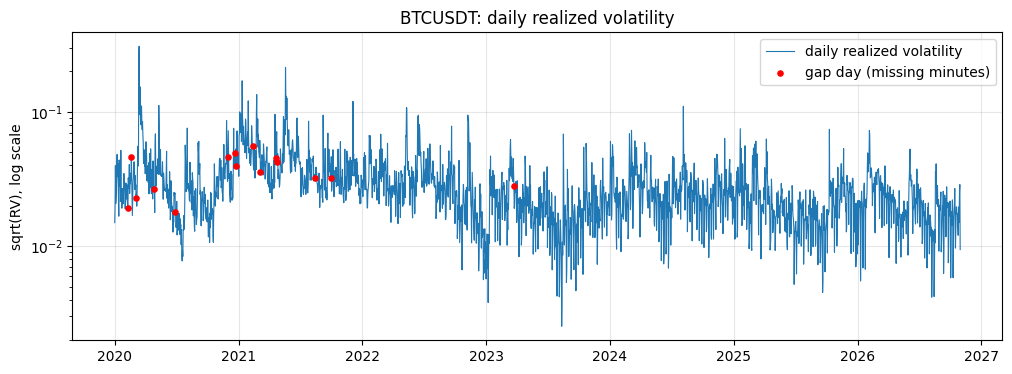

[BTCUSDT] full-sample HAR + sat/sun/mon: R2 0.700 | persistence 0.924 | volatility multipliers vs Tue-Fri: Sat x0.60, Sun x0.91, Mon x1.19
[BTCUSDT] weekday dummy coefficients by year (HAC s.e.):


,n,sat,sun,mon,sat_se,sun_se,mon_se
year,,,,,,,
2020,344,-0.348,-0.063,0.183,0.079,0.100,0.094
2021,365,-0.358,-0.183,0.170,0.088,0.071,0.102
2022,365,-0.953,-0.249,0.304,0.085,0.093,0.101
2023,365,-1.326,-0.316,0.375,0.114,0.118,0.117
2024,366,-1.289,-0.397,0.381,0.107,0.109,0.101
2025,365,-1.399,-0.048,0.476,0.092,0.117,0.093
2026,304,-1.399,-0.021,0.495,0.121,0.108,0.081


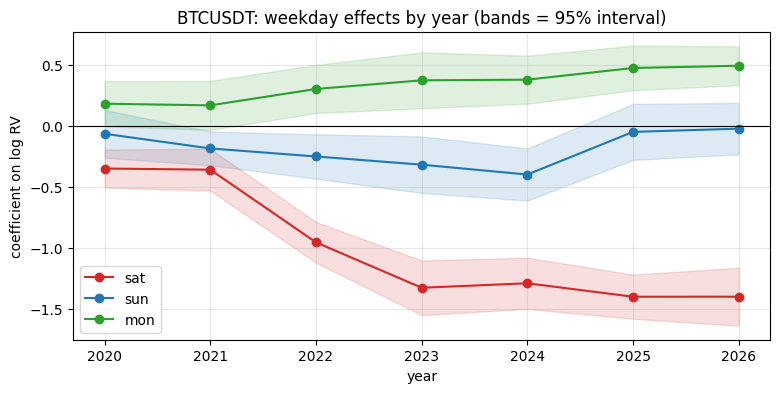


[BTCUSDT | period 2023-24 (2023-01-01 .. 2024-12-31) | forecasts per horizon {1: 731, 7: 725, 28: 704}] primary tests:


,test,statistic,p_value,p_holm,passes
0,1. dummies vs HAR (h=1),11.03,2.815e-28,1.408e-27,True
1,2. fixed window vs expanding (h=1),5.229,1.704e-07,5.112e-07,True
2,"3. HAR vs AR(1), nested (h=1)",7.703,6.622e-15,2.649e-14,True
3,"4. HAR vs weekly-only, nested (h=7)",4.066,2.394e-05,4.788e-05,True
4,"5. HAR vs weekly-only, nested (h=28) [explorat...",2.687,0.003607,0.003607,True



[BTCUSDT | period 2025-26 (2025-01-01 .. end of data) | forecasts per horizon {1: 669, 7: 663, 28: 642}] primary tests:


,test,statistic,p_value,p_holm,passes
0,1. dummies vs HAR (h=1),10.59,3.146e-26,1.573e-25,True
1,2. fixed window vs expanding (h=1),3.628,0.0002855,0.000571,True
2,"3. HAR vs AR(1), nested (h=1)",3.879,5.251e-05,0.0001575,True
3,"4. HAR vs weekly-only, nested (h=7)",4.515,3.166e-06,1.266e-05,True
4,"5. HAR vs weekly-only, nested (h=28) [explorat...",1.076,0.141,0.141,False



[BTCUSDT | period 2023-26_pooled (2023-01-01 .. end of data) | forecasts per horizon {1: 1400, 7: 1394, 28: 1373}] primary tests:


,test,statistic,p_value,p_holm,passes
0,1. dummies vs HAR (h=1),15.09,1.757e-51,8.784e-51,True
1,2. fixed window vs expanding (h=1),6.21,5.31e-10,1.593e-09,True
2,"3. HAR vs AR(1), nested (h=1)",8.288,5.747e-17,2.299e-16,True
3,"4. HAR vs weekly-only, nested (h=7)",5.794,3.441e-09,6.882e-09,True
4,"5. HAR vs weekly-only, nested (h=28) [explorat...",2.785,0.002676,0.002676,True


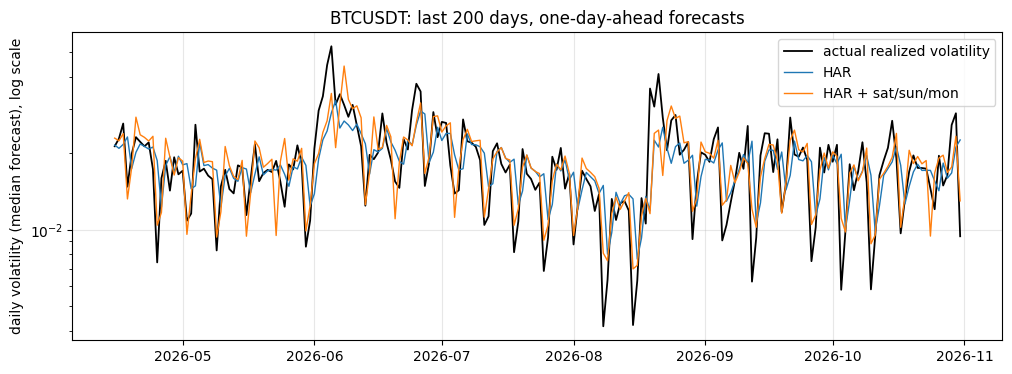

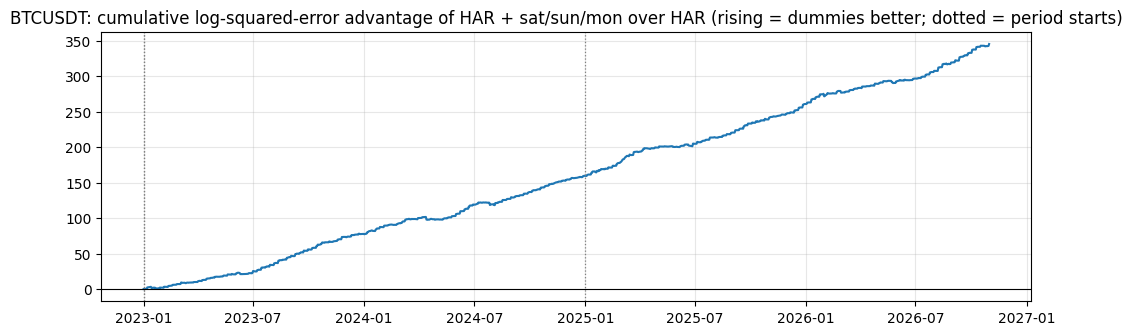


============================== ETHUSDT ==============================


ETHUSDT:   0%|          | 0/82 [00:00<?, ?it/s]

[ETHUSDT] 2496 days 2020-01-01 .. 2026-10-31 | missing days 0 OK | bad RV values 0 OK | outside range 0 OK | gap days 15 (0.6%)


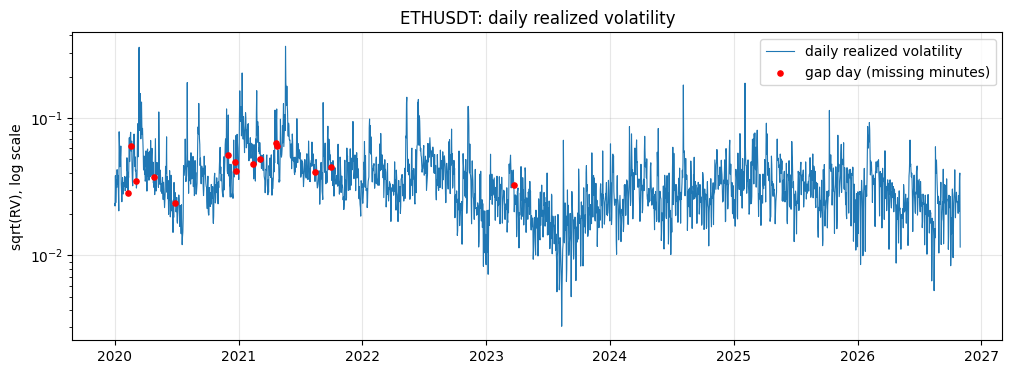

[ETHUSDT] full-sample HAR + sat/sun/mon: R2 0.687 | persistence 0.925 | volatility multipliers vs Tue-Fri: Sat x0.68, Sun x0.93, Mon x1.14
[ETHUSDT] weekday dummy coefficients by year (HAC s.e.):


,n,sat,sun,mon,sat_se,sun_se,mon_se
year,,,,,,,
2020,344,-0.293,-0.013,0.106,0.087,0.109,0.076
2021,365,-0.305,-0.166,0.143,0.078,0.082,0.104
2022,365,-0.751,-0.248,0.212,0.087,0.080,0.094
2023,365,-0.988,-0.252,0.254,0.103,0.110,0.092
2024,366,-0.976,-0.312,0.339,0.089,0.098,0.111
2025,365,-0.971,-0.053,0.358,0.093,0.104,0.098
2026,304,-1.173,0.121,0.416,0.129,0.103,0.073


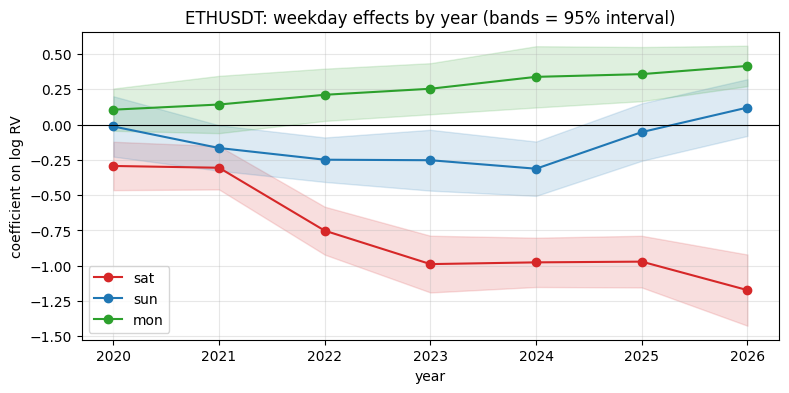


[ETHUSDT | period 2023-24 (2023-01-01 .. 2024-12-31) | forecasts per horizon {1: 731, 7: 725, 28: 704}] primary tests:


,test,statistic,p_value,p_holm,passes
0,1. dummies vs HAR (h=1),9.735,2.131e-22,1.065e-21,True
1,2. fixed window vs expanding (h=1),4.037,5.421e-05,0.0001084,True
2,"3. HAR vs AR(1), nested (h=1)",9.531,7.795e-22,3.118e-21,True
3,"4. HAR vs weekly-only, nested (h=7)",5.838,2.637e-09,7.912e-09,True
4,"5. HAR vs weekly-only, nested (h=28) [explorat...",3.625,0.0001442,0.0001442,True



[ETHUSDT | period 2025-26 (2025-01-01 .. end of data) | forecasts per horizon {1: 669, 7: 663, 28: 642}] primary tests:


,test,statistic,p_value,p_holm,passes
0,1. dummies vs HAR (h=1),8.151,3.598e-16,1.799e-15,True
1,2. fixed window vs expanding (h=1),2.11,0.03485,0.03485,True
2,"3. HAR vs AR(1), nested (h=1)",5.53,1.603e-08,6.413e-08,True
3,"4. HAR vs weekly-only, nested (h=7)",4.821,7.141e-07,2.142e-06,True
4,"5. HAR vs weekly-only, nested (h=28) [explorat...",2.536,0.005607,0.01121,True



[ETHUSDT | period 2023-26_pooled (2023-01-01 .. end of data) | forecasts per horizon {1: 1400, 7: 1394, 28: 1373}] primary tests:


,test,statistic,p_value,p_holm,passes
0,1. dummies vs HAR (h=1),12.22,2.493e-34,1.246e-33,True
1,2. fixed window vs expanding (h=1),4.171,3.029e-05,3.029e-05,True
2,"3. HAR vs AR(1), nested (h=1)",10.52,3.48e-26,1.392e-25,True
3,"4. HAR vs weekly-only, nested (h=7)",7.528,2.569e-14,7.708e-14,True
4,"5. HAR vs weekly-only, nested (h=28) [explorat...",4.386,5.778e-06,1.156e-05,True


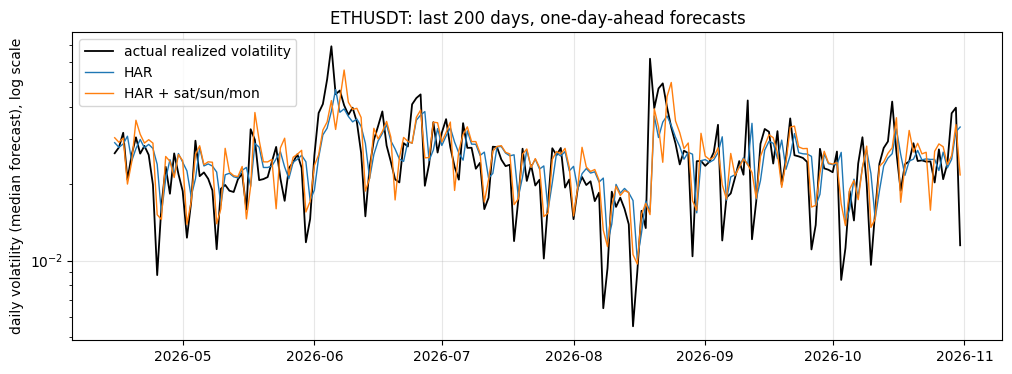

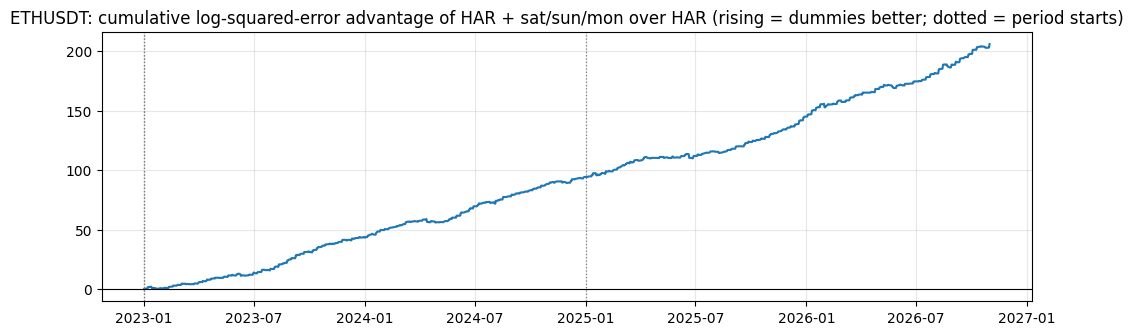


SCORECARD (pass = statistic > 0 and Holm p < 0.05 over the five primary tests, per asset and period):


,test,BTC 2023-24,BTC 2025-26,BTC 2023-26_pooled,ETH 2023-24,ETH 2025-26,ETH 2023-26_pooled,pass in every run
0,1. dummies vs HAR (h=1),pass,pass,pass,pass,pass,pass,YES
1,2. fixed window vs expanding (h=1),pass,pass,pass,pass,pass,pass,YES
2,"3. HAR vs AR(1), nested (h=1)",pass,pass,pass,pass,pass,pass,YES
3,"4. HAR vs weekly-only, nested (h=7)",pass,pass,pass,pass,pass,pass,YES
4,"5. HAR vs weekly-only, nested (h=28) [explorat...",pass,FAIL,pass,pass,pass,pass,exploratory (not judged)


Numbers behind it:


,test,BTC 2023-24 | stat,BTC 2023-24 | p_holm,BTC 2025-26 | stat,BTC 2025-26 | p_holm,BTC 2023-26_pooled | stat,BTC 2023-26_pooled | p_holm,ETH 2023-24 | stat,ETH 2023-24 | p_holm,ETH 2025-26 | stat,ETH 2025-26 | p_holm,ETH 2023-26_pooled | stat,ETH 2023-26_pooled | p_holm
0,1. dummies vs HAR (h=1),11.03,1.408e-27,10.59,1.573e-25,15.09,8.784e-51,9.735,1.065e-21,8.151,1.799e-15,12.22,1.246e-33
1,2. fixed window vs expanding (h=1),5.229,5.112e-07,3.628,0.000571,6.21,1.593e-09,4.037,0.0001084,2.11,0.03485,4.171,3.029e-05
2,"3. HAR vs AR(1), nested (h=1)",7.703,2.649e-14,3.879,0.0001575,8.288,2.299e-16,9.531,3.118e-21,5.53,6.413e-08,10.52,1.392e-25
3,"4. HAR vs weekly-only, nested (h=7)",4.066,4.788e-05,4.515,1.266e-05,5.794,6.882e-09,5.838,7.912e-09,4.821,2.142e-06,7.528,7.708e-14
4,"5. HAR vs weekly-only, nested (h=28) [explorat...",2.687,0.003607,1.076,0.141,2.785,0.002676,3.625,0.0001442,2.536,0.01121,4.386,1.156e-05



Saved: output/replication_all.csv, output/replication_scorecard.csv and one folder per asset under /content/drive/MyDrive/HF/output


In [10]:
ALL = {}
for sym in SYMBOLS:
    print("\n" + "=" * 30, sym, "=" * 30)
    ALL[sym] = run_symbol(sym)

# ---- numeric table: statistic and Holm p-value of every primary test in every run ----
cmp = None
for sym, res in ALL.items():
    for per, r in res.items():
        run = f"{sym.replace('USDT', '')} {per}"
        pt = r["primary"][["test", "statistic", "p_holm"]].copy()
        pt.columns = ["test", f"{run} | stat", f"{run} | p_holm"]
        cmp = pt if cmp is None else cmp.merge(pt, on="test")
stat_cols = [c for c in cmp.columns if c.endswith("| stat")]
holm_cols = [c for c in cmp.columns if c.endswith("| p_holm")]

# ---- scorecard ----
score_tab = pd.DataFrame({"test": cmp["test"]})
for s, h_ in zip(stat_cols, holm_cols):
    score_tab[s.replace(" | stat", "")] = np.where((cmp[s] > 0) & (cmp[h_] < 0.05), "pass", "FAIL")
runs_cols = [c for c in score_tab.columns if c != "test"]
confirmatory = ~score_tab["test"].str.contains("exploratory")
all_pass = (score_tab[runs_cols] == "pass").all(axis=1)
score_tab["pass in every run"] = np.where(~confirmatory, "exploratory (not judged)", np.where(all_pass, "YES", "no"))

print("\nSCORECARD (pass = statistic > 0 and Holm p < 0.05 over the five primary tests, per asset and period):")
display(score_tab)
print("Numbers behind it:")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(cmp)
cmp.to_csv(ROOT_OUT / "replication_all.csv", index=False)
score_tab.to_csv(ROOT_OUT / "replication_scorecard.csv", index=False)
print("\nSaved: output/replication_all.csv, output/replication_scorecard.csv and one folder per asset under", ROOT_OUT)


In [11]:
!ls -R /content/drive/MyDrive/HF/output | head -60

/content/drive/MyDrive/HF/output:
BTCUSDT
ETHUSDT
replication_all.csv
replication_scorecard.csv

/content/drive/MyDrive/HF/output/BTCUSDT:
BTCUSDT_daily_rv.csv
config.json
figures
periods
yearly_weekday_effects.csv

/content/drive/MyDrive/HF/output/BTCUSDT/figures:
01_daily_realized_vol.png
02_weekday_effects_by_year.png
03_forecasts_h1.png
04_cumulative_advantage.png

/content/drive/MyDrive/HF/output/BTCUSDT/periods:
2023-24
2023-26_pooled
2025-26

/content/drive/MyDrive/HF/output/BTCUSDT/periods/2023-24:
primary_tests.csv
results_h1.csv
results_h28.csv
results_h7.csv
tests.csv
window_sensitivity.csv

/content/drive/MyDrive/HF/output/BTCUSDT/periods/2023-26_pooled:
primary_tests.csv
results_h1.csv
results_h28.csv
results_h7.csv
tests.csv
window_sensitivity.csv

/content/drive/MyDrive/HF/output/BTCUSDT/periods/2025-26:
primary_tests.csv
results_h1.csv
results_h28.csv
results_h7.csv
tests.csv
window_sensitivity.csv

/content/drive/MyDrive/HF/output/ETHUSDT:
config.json
ETHUSDT_daily_rv.

In [12]:
!rm -rf /content/reports && mkdir -p /content/reports/phase1_results
!cp -r /content/drive/MyDrive/HF/output/BTCUSDT /content/drive/MyDrive/HF/output/ETHUSDT /content/drive/MyDrive/HF/output/replication_all.csv /content/drive/MyDrive/HF/output/replication_scorecard.csv /content/reports/phase1_results/
!rm -f /content/reports/phase1_results/*/*_daily_rv.csv
!cd /content && zip -rq reports.zip reports
!find /content/reports -type f | wc -l
!ls /content/reports/phase1_results/ETHUSDT/periods/*
from google.colab import files
files.download("/content/reports.zip")

50
/content/reports/phase1_results/ETHUSDT/periods/2023-24:
primary_tests.csv  results_h28.csv  tests.csv
results_h1.csv	   results_h7.csv   window_sensitivity.csv

/content/reports/phase1_results/ETHUSDT/periods/2023-26_pooled:
primary_tests.csv  results_h28.csv  tests.csv
results_h1.csv	   results_h7.csv   window_sensitivity.csv

/content/reports/phase1_results/ETHUSDT/periods/2025-26:
primary_tests.csv  results_h28.csv  tests.csv
results_h1.csv	   results_h7.csv   window_sensitivity.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## How to read the results
1. **Section 2 lines**: missing days must be 0; a few gap days are normal for older Binance data.
2. **Weekday tables (Section 5 output)**: are Saturday and Monday effects significant in recent years, and do they drift?
3. **Primary tests per period**: five rows each, with Holm p-values.
4. **Scorecard (Section 7)**: do tests 1-4 pass in every asset and period? Test 5 is exploratory.
5. Full tables are in the output folders (`results_h1.csv`, `results_h7.csv`, `results_h28.csv`, `window_sensitivity.csv`, `tests.csv`). Set `VERBOSE = True` to print them all.

## Changing things
* **Another asset**: add it to `SYMBOLS` (for example `"SOLUSDT"`). Only the new asset is downloaded.
* **Another period**: add an entry to `TEST_PERIODS`. Periods that start earlier than about 2022-03 get a shorter training window than `WINDOW`, so keep them at or after that.
* **Another window or horizon**: `WINDOW`, `WINDOW_GRID`, `HORIZONS`. The primary tests assume h = 1, 7 and 28.
* The primary hypotheses were fixed after looking at BTC 2025-26. Do not change them after seeing the replication results.

## Next steps
* **Extensions**: jump-robust RV (bipower variation), a time trend in the weekday dummies, intraday seasonality.
* **Writing**: the scorecard and `replication_all.csv` give the main results table; the yearly weekday plots are the main figure.